# Извлечение признаков: RBM, PCA и исходные пиксели

## 1. Данные

MNIST: 60 000 изображений для обучения, 10 000 для теста. Размер — 28×28.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from zipfile import BadZipFile
from threadpoolctl import threadpool_limits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
threadpool_limits(2)

path = Path('mnist.npz')
from urllib.request import urlretrieve
urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', str(path))

Train: (60000, 784) Test: (10000, 784)


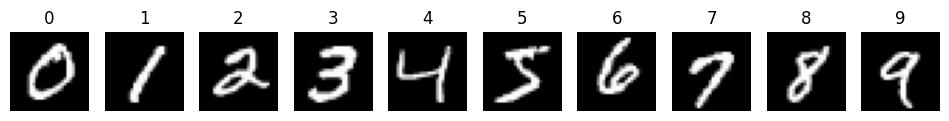

In [ ]:
with np.load('mnist.npz') as data:
    X_train = data['x_train'].reshape(-1, 784).astype('float32') / 255
    X_test = data['x_test'].reshape(-1, 784).astype('float32') / 255
    y_train, y_test = data['y_train'], data['y_test']

print('Train:', X_train.shape, 'Test:', X_test.shape)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for digit, ax in enumerate(axes):
    i = np.flatnonzero(y_train == digit)[0]
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(digit))
    ax.axis('off')
plt.show()

## 2. Модели

Pixels: 784 признака; PCA и RBM: по 256. Во всех случаях классификатор - Logistic Regression.

In [ ]:
class RBM:
    def __init__(self, hidden=256):
        self.hidden = hidden

    def fit(self, X, epochs=15, batch_size=256, lr=0.05):
        X = torch.from_numpy(X)
        rng = torch.Generator().manual_seed(42 + self.hidden)
        W = torch.randn(784, self.hidden, generator=rng) * 0.01
        hb = torch.zeros(self.hidden)
        p = X.mean(0).clamp(0.01, 0.99)
        vb = torch.log(p / (1 - p))
        vW, vh, vv = torch.zeros_like(W), torch.zeros_like(hb), torch.zeros_like(vb)

        for epoch in range(epochs):
            for indices in torch.randperm(len(X), generator=rng).split(batch_size):
                v0 = X[indices]
                ph0 = torch.sigmoid(v0 @ W + hb)
                h0 = torch.bernoulli(ph0, generator=rng)
                pv1 = torch.sigmoid(h0 @ W.T + vb)
                v1 = torch.bernoulli(pv1, generator=rng)
                ph1 = torch.sigmoid(v1 @ W + hb)
                dW = (v0.T @ ph0 - v1.T @ ph1) / len(indices) - 1e-4 * W
                dh = (ph0 - ph1).mean(0)
                dv = (v0 - v1).mean(0)
                vW = 0.5 * vW + lr * dW
                vh = 0.5 * vh + lr * dh
                vv = 0.5 * vv + lr * dv
                W += vW
                hb += vh
                vb += vv
            if epoch in (0, 4, 9, 14):
                print(f'RBM: эпоха {epoch + 1}/{epochs}')

        self.W, self.hb = W, hb
        return self

    def transform(self, X):
        with torch.no_grad():
            return torch.sigmoid(torch.from_numpy(X) @ self.W + self.hb).numpy()

## 3. Подбор признаков на валидации

In [ ]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=10000, stratify=y_train, random_state=42)

val_rows = []
for method in ('Pixels', 'PCA', 'RBM'):
    for k in ((784,) if method == 'Pixels' else (32, 64, 128, 256)):
        if method == 'Pixels':
            train, val = X_fit, X_val
        elif method == 'PCA':
            model = PCA(n_components=k, svd_solver='randomized',
                        n_oversamples=12, iterated_power=4, random_state=42)
            train, val = model.fit_transform(X_fit), model.transform(X_val)
        else:
            model = RBM(k).fit(X_fit)
            train, val = model.transform(X_fit), model.transform(X_val)
        scaler = StandardScaler()
        train, val = scaler.fit_transform(train), scaler.transform(val)
        candidates = []
        for C in (0.1, 1.0, 10.0):
            clf = LogisticRegression(C=C, max_iter=300, tol=0.0005, random_state=42)
            clf.fit(train, y_fit)
            pred = clf.predict(val)
            candidates.append((accuracy_score(y_val, pred),
                               f1_score(y_val, pred, average='macro'), -C))
        acc, f1, minus_C = max(candidates)
        val_rows.append((method, k, -minus_C, acc, f1))

validation = pd.DataFrame(val_rows, columns=['Метод', 'Признаков', 'C', 'Accuracy', 'Macro-F1'])
print(validation.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

RBM: эпоха 1/15


RBM: эпоха 5/15


RBM: эпоха 10/15


RBM: эпоха 15/15


RBM: эпоха 1/15


RBM: эпоха 5/15


... (7 outputs left out)

RBM: эпоха 5/15


RBM: эпоха 10/15


RBM: эпоха 15/15


 Метод  Признаков       C  Accuracy  Macro-F1
Pixels        784  0.1000    0.9188    0.9178
   PCA         32 10.0000    0.8957    0.8944
   PCA         64 10.0000    0.9105    0.9094
   PCA        128  0.1000    0.9180    0.9171
   PCA        256  1.0000    0.9208    0.9198
   RBM         32  0.1000    0.8779    0.8757
   RBM         64 10.0000    0.9118    0.9105
   RBM        128  1.0000    0.9395    0.9389
   RBM        256  0.1000    0.9578    0.9574


In [ ]:
pca = PCA(n_components=256, svd_solver='randomized',
          n_oversamples=12, iterated_power=4, random_state=42)
rbm = RBM(256)

features = {
    'Pixels': (X_train, X_test),
    'PCA': (pca.fit_transform(X_train), pca.transform(X_test)),
    'RBM': (rbm.fit(X_train).transform(X_train), rbm.transform(X_test))
}

RBM: эпоха 1/15


RBM: эпоха 5/15


RBM: эпоха 10/15


RBM: эпоха 15/15


In [ ]:
rows, predictions = [], {}
for name, (train, test) in features.items():
    scaler = StandardScaler()
    train = scaler.fit_transform(train)
    test = scaler.transform(test)
    clf = LogisticRegression(C=1.0 if name == 'PCA' else 0.1,
                             max_iter=300, tol=0.0005, random_state=42)
    clf.fit(train, y_train)
    pred = clf.predict(test)
    predictions[name] = pred
    rows.append([name, train.shape[1], accuracy_score(y_test, pred),
                 f1_score(y_test, pred, average='macro')])

results = pd.DataFrame(rows, columns=['Модель', 'Признаков', 'Accuracy', 'Macro-F1'])
print(results.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Модель  Признаков  Accuracy  Macro-F1
Pixels        784    0.9255    0.9244
   PCA        256    0.9253    0.9242
   RBM        256    0.9614    0.9610


## 4. Результаты

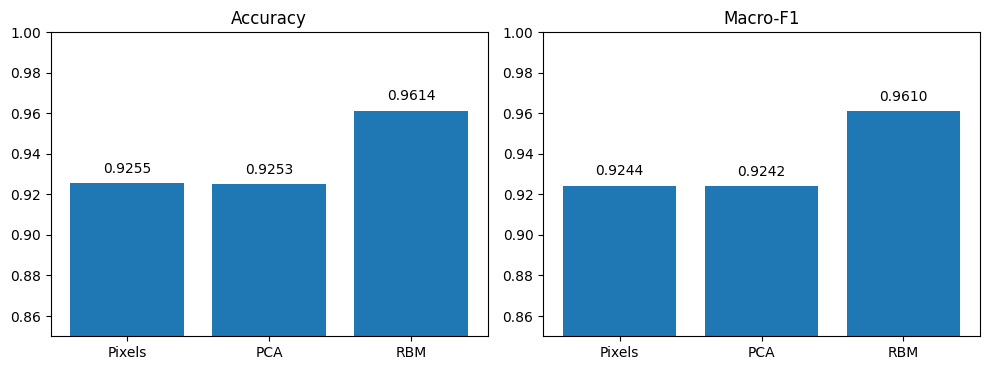

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, metric in zip(axes, ['Accuracy', 'Macro-F1']):
    ax.bar(results['Модель'], results[metric])
    ax.set_title(metric)
    ax.set_ylim(0.85, 1.00)
    for i, value in enumerate(results[metric]):
        ax.text(i, value + 0.005, f'{value:.4f}', ha='center')
plt.tight_layout()
plt.show()

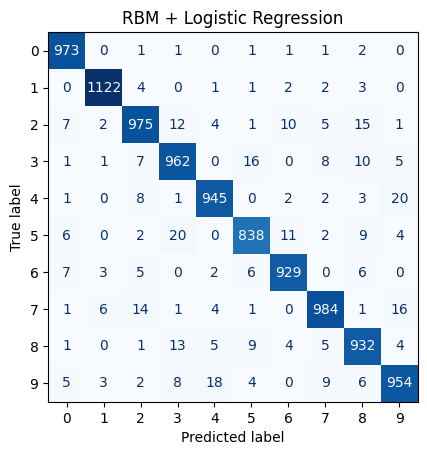

Частые ошибки RBM: 5 → 3 (20), 4 → 9 (20), 9 → 4 (18)


In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions['RBM'],
                                        cmap='Blues', colorbar=False)
plt.title('RBM + Logistic Regression')
plt.show()
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions['RBM'])
np.fill_diagonal(cm, 0)
indices = np.argsort(cm.ravel())[-3:][::-1]
pairs = [(*np.unravel_index(int(i), cm.shape), int(cm.ravel()[i])) for i in indices]
print('Частые ошибки RBM:', ', '.join(f'{a} → {b} ({n})' for a, b, n in pairs))

## 5. Скрытые признаки RBM

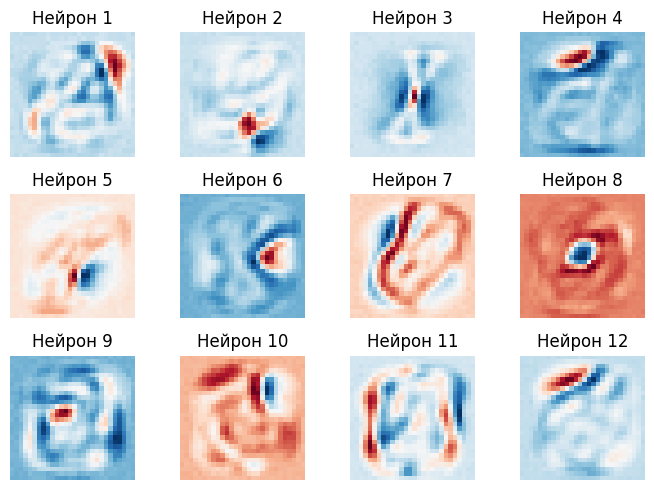

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(7, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(rbm.W[:, i].reshape(28, 28), cmap='RdBu_r')
    ax.set_title(f'Нейрон {i + 1}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Вывод

In [ ]:
best = results.loc[results['Accuracy'].idxmax()]
print(f"Лучшая модель — {best['Модель']} (Accuracy = {best['Accuracy']:.4f})")
acc = results.set_index('Модель')['Accuracy']
print(f"RBM относительно пикселей: +{100*(acc['RBM']-acc['Pixels']):.2f} п.п.")
print('PCA сокращает 784 пикселя до 256 признаков без заметной потери Accuracy.')

Лучшая модель — RBM (Accuracy = 0.9614)
RBM относительно пикселей: +3.59 п.п.
PCA сокращает 784 пикселя до 256 признаков без заметной потери Accuracy.
